<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/03_%E6%95%B8%E6%93%9A%E5%88%86%E5%89%B2/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. 數據分割 (Data Splitting)

在機器學習中，不可拿訓練過的資料來評估模型（避免數據洩漏與偷看答案）。
本範例使用繁體中文「客戶違約資料集」示範：
1. **隨機分割** vs **分層抽樣 (Stratified Sampling)**。
2. 使用 Seaborn 視覺化比較兩者的類別比例分佈。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 讀取繁體中文客戶違約資料
df = pd.read_csv('客戶違約資料集.csv')
print("=== 資料集摘要 ===")
print(df.head())

X = df[['年齡', '年收入_萬元', '信用評分']]
y = df['是否違約']

print(f"\n原始資料總筆數: {len(df)}")
print("原始標籤分佈比例：")
print(y.value_counts(normalize=True).map('{:.1%}'.format))


=== 資料集摘要 ===
   年齡  年收入_萬元  信用評分 是否違約
0  60     169   678   正常
1  50     106   816   違約
2  36      46   700   正常
3  64      67   648   正常
4  29      82   812   正常

原始資料總筆數: 100
原始標籤分佈比例：
是否違約
正常    85.0%
違約    15.0%
Name: proportion, dtype: str


In [4]:
# 1. 一般隨機抽樣 vs 分層抽樣
# 一般隨機抽樣
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y, test_size=0.2, random_state=123)

# 分層抽樣 (stratify=y)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X, y, test_size=0.2, random_state=123, stratify=y)

# 計算違約比例
r_test_ratio = np.mean(y_test_r == '違約')
s_test_ratio = np.mean(y_test_s == '違約')
orig_ratio = np.mean(y == '違約')

print("=== 違約樣本比例對照 ===")
print(f"原始母體違約比例:   {orig_ratio:.1%}")
print(f"隨機抽樣測試集違約: {r_test_ratio:.1%} (產生抽樣偏差)")
print(f"分層抽樣測試集違約: {s_test_ratio:.1%} (精準吻合母體)")


=== 違約樣本比例對照 ===
原始母體違約比例:   15.0%
隨機抽樣測試集違約: 5.0% (產生抽樣偏差)
分層抽樣測試集違約: 15.0% (精準吻合母體)


/var/folders/7g/kb_wcfhj3710_xnyqdgx_v940000gn/T/ipykernel_13805/3515375496.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=compare_df, x='資料集類型', y='違約比例', palette='Blues_d')


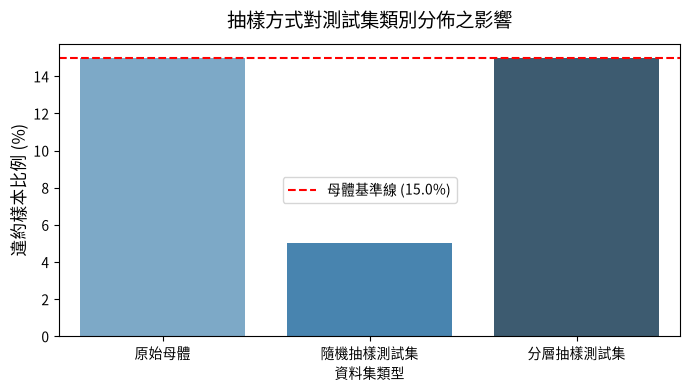

💡 觀念總結：在分類不平衡情境中，務必啟用 stratify=y 保持分佈一致性！


In [5]:
# 2. 繪製違約率對比長條圖
compare_df = pd.DataFrame({
    '資料集類型': ['原始母體', '隨機抽樣測試集', '分層抽樣測試集'],
    '違約比例': [orig_ratio * 100, r_test_ratio * 100, s_test_ratio * 100]
})

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=compare_df, x='資料集類型', y='違約比例', palette='Blues_d')
plt.title('抽樣方式對測試集類別分佈之影響', fontsize=14, pad=12)
plt.ylabel('違約樣本比例 (%)', fontsize=12)
plt.axhline(orig_ratio * 100, color='red', linestyle='--', label=f'母體基準線 ({orig_ratio:.1%})')
plt.legend()
plt.tight_layout()
plt.show()

print("💡 觀念總結：在分類不平衡情境中，務必啟用 stratify=y 保持分佈一致性！")
